# Lesson 15: House-price regression with PyTorch

Train a feed-forward neural network on ParisHousing data. Run from this directory with NumPy, scikit-learn, Matplotlib, and PyTorch installed.

**Data:** [Paris Housing Price Prediction](https://www.kaggle.com/datasets/mssmartypants/paris-housing-price-prediction). Place `ParisHousing.csv` in this lesson folder.

In [1]:
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(1)
data = np.loadtxt("ParisHousing.csv", delimiter=",", skiprows=1)
X, y = data[:, :-1], data[:, -1].reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train)
train_x, val_x, test_x = (torch.tensor(x_scaler.transform(x), dtype=torch.float32)
                          for x in (X_train, X_val, X_test))
train_y = torch.tensor(y_scaler.transform(y_train), dtype=torch.float32)
val_y = torch.tensor(y_scaler.transform(y_val), dtype=torch.float32)
loader = DataLoader(TensorDataset(train_x, train_y), batch_size=64, shuffle=True)

## Train and validate

Fit the scalers and model on the training split. Monitor the separate validation split after each epoch. Loss is mean squared error on standardized prices.

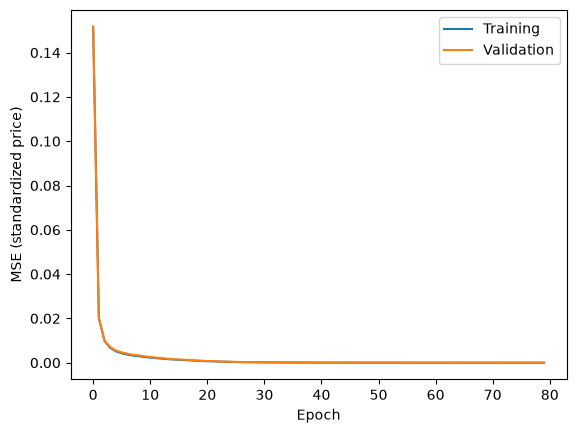

In [2]:
model = nn.Sequential(nn.Linear(train_x.shape[1], 32), nn.ReLU(),
                      nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters())
train_loss, val_loss = [], []
for epoch in range(80):
    model.train()
    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        loss = criterion(model(batch_x), batch_y)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        train_loss.append(criterion(model(train_x), train_y).item())
        val_loss.append(criterion(model(val_x), val_y).item())

plt.plot(train_loss, label="Training")
plt.plot(val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized price)")
plt.legend()
plt.show()

## Evaluate

Transform predictions back to the dataset’s price units before calculating test MAE.

In [3]:
model.eval()
with torch.no_grad():
    predicted = y_scaler.inverse_transform(model(test_x).numpy())
print(f"Test MAE: {mean_absolute_error(y_test, predicted):,.2f}")

Test MAE: 7,267.21
